In [1]:
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd

from juego_piedras_bt import juego_piedras, Color
from util import time_algorithm

In [2]:
#generamos tableros aleatorios como una instancia de pruebas utilizando el doble de filas que de columnas
#Esto es con el fin de aumentar proporcionalmente la cantidad de filas al aumentar la cantidad de columnas
def generar_aleatorio(m):
    n = 2 * m

    valores = np.random.choice(
        [0, 1, 2],
        size=(n, m),
        p=[0.35, 0.325, 0.325]
    )

    tablero = [
        [Color(int(celda)) for celda in fila]
        for fila in valores
    ]

    return tablero

#Generamos un caso de comportammiento exponencial: nunca se activa la condicion de mejor_vacias == 0
def generar_peor_caso(m):
    tablero = [
        [Color.VACIO] * m
        for _ in range(2 * m)
    ]

    for j in range(m):
        tablero[2 * j][j] = Color.VERDE
        tablero[2 * j + 1][j] = Color.CELESTE

    return tablero

In [3]:
x = np.arange(2, 13)

np.random.seed(12345)

resultados_aleatorios = time_algorithm(
    juego_piedras,
    x,
    lambda m: [generar_aleatorio(m)],
    runs_per_size=50
)

resultados_peor_caso = time_algorithm(
    juego_piedras,
    x,
    lambda m: [generar_peor_caso(m)],
    runs_per_size=10
)

In [4]:
tabla = pd.DataFrame({
    "Aleatorio": resultados_aleatorios,
    "Peor caso": resultados_peor_caso
})

tabla.index.name = "Cantidad de columnas"

display(tabla)

,Aleatorio,Peor caso
Cantidad de columnas,,
2,0.000012,0.000020
3,0.000036,0.000056
4,0.000078,0.000227
5,0.000141,0.000989
6,0.000115,0.003534
7,0.000157,0.014602
8,0.000082,0.059080
9,0.001274,0.187366
10,0.000110,0.744175


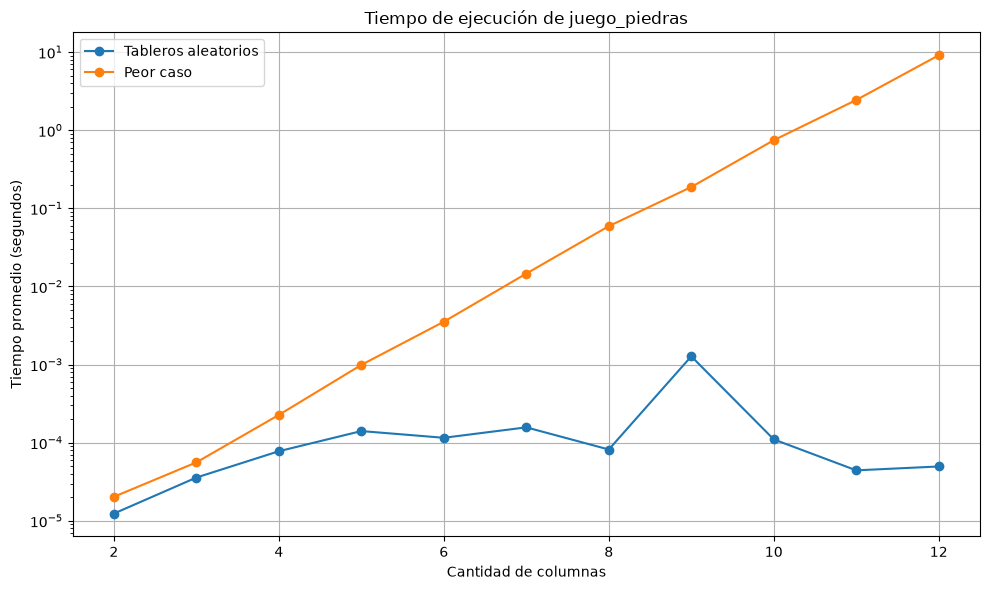

In [5]:
plt.figure(figsize=(10, 6))

plt.plot(
    x,
    tabla["Aleatorio"],
    marker="o",
    label="Tableros aleatorios"
)

plt.plot(
    x,
    tabla["Peor caso"],
    marker="o",
    label="Peor caso"
)

plt.xlabel("Cantidad de columnas")
plt.ylabel("Tiempo promedio (segundos)")
plt.title("Tiempo de ejecución de juego_piedras")
plt.yscale("log")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig("mediciones_bt.png", dpi=300, bbox_inches="tight")
plt.show()